In [ ]:
!pip install kagglehub
import pandas as pd
import numpy as np
import re
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')
from nltk.stem.isri import ISRIStemmer

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [ ]:
import kagglehub
import os
import pandas as pd

# download from Kaggle
dataset_path = kagglehub.dataset_download("haithemhermessi/sanad-dataset")

print("Path to dataset files:", dataset_path)

texts = []
labels = []

for label in os.listdir(dataset_path):
    label_path = os.path.join(dataset_path, label)


    if not os.path.isdir(label_path):
        continue

    for file_name in os.listdir(label_path):
        if file_name.endswith(".txt"):
            file_path = os.path.join(label_path, file_name)

            with open(file_path, "r", encoding="utf-8") as f:
                text = f.read().strip()

                texts.append(text)
                labels.append(label)

#  DataFrame
df = pd.DataFrame({
    "text": texts,
    "label": labels
})

print(df.head())

Using Colab cache for faster access to the 'sanad-dataset' dataset.
Path to dataset files: /kaggle/input/sanad-dataset
                                                text    label
0  دبي - "الخليج":حصدت شعاع كابيتال جائزة "أفضل ش...  Finance
1  أبوظبي - علي أسعد: تراجعت أسواق المال في الدول...  Finance
2  استأنفت أسواق الأسهم المحلية أمس تحركها باتجاه...  Finance
3  دبي «الخليج»: أعلنت شركة تكافل الإمارات عن بدء...  Finance
4  تحتفل شركة طاقة الخليج البحرية، التي تتخذ من د...  Finance


In [ ]:
df.head(10)

,text,label
0,"دبي - ""الخليج"":حصدت شعاع كابيتال جائزة ""أفضل ش...",Finance
1,أبوظبي - علي أسعد: تراجعت أسواق المال في الدول...,Finance
2,استأنفت أسواق الأسهم المحلية أمس تحركها باتجاه...,Finance
3,دبي «الخليج»: أعلنت شركة تكافل الإمارات عن بدء...,Finance
4,تحتفل شركة طاقة الخليج البحرية، التي تتخذ من د...,Finance
5,تأجيل عمومية الدارأبوظبي - الخليج: تأجل اجتماع...,Finance
6,غلبت السلبية والإغلاقات الحمراء على مؤشرات أسو...,Finance
7,أبوظبي «الخليج»: ارتفع مؤشر سوق الإمارات المال...,Finance
8,أبوظبي:«الخليج» واصل مؤشر سوق أبوظبي للأوراق ا...,Finance
9,أبوظبي الخليج: أعاد بنك الشارقة شراء 5،5 مليون...,Finance


In [ ]:
df = df.sample(frac=1).reset_index(drop=True)

In [ ]:
df.head(10)

,text,label
0,نظمت المؤسسة العربية للعلوم والتكنولوجيا بالتع...,Tech
1,كل دارس موضوعي ومنصف لمسيرة رسولنا العظيم صلى ...,Religion
2,تواصلت مساء أمس الأول في مكناس في المغرب جلسات...,Culture
3,استضاف بيت الشعر في أبوظبي مساء أمس الأول الدك...,Culture
4,"القاهرة - ""الخليج"":تشهد انتخابات رئاسة حزب الو...",Politics
5,أكمل فريق لايبزج الألماني لكرة القدم، تعاقده م...,Sports
6,حذر المنسق الإقليمي للاجئين في الأمم المتحدة ب...,Politics
7,القاهرة: «الخليج» عالم من علماء اللغة العربية ...,Religion
8,الشارقة - عايدة عبدالحميد:أعلن محمد عبدالله ال...,Medical
9,قبل 24 ساعة من موعد «الكلاسيكو» بين ريال مدريد...,Sports


In [ ]:
mapping = {
    'Religion': 0,
    'Politics': 1,
    'Sports': 2,
    'Medical': 3,
    'Finance': 4,
    'Culture': 5,
    'Tech': 6
}

df['label'] = df['label'].astype(str).str.strip().map(mapping)

Split Data

In [ ]:
X = df['text']
y = df['label']

# Drop rows where 'y' (label) is NaN
missing_labels_mask = y.isna()
X = X[~missing_labels_mask]
y = y[~missing_labels_mask]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

Tokenizer

In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

max_words = 50000
max_len = 100

tokenizer = Tokenizer(num_words=max_words, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

In [ ]:
# ML Tokenizer (TF-IDF)
from sklearn.feature_extraction.text import TfidfVectorizer

max_features = 50000

vectorizer = TfidfVectorizer(max_features=max_features)
vectorizer.fit(X_train)

TfidfVectorizer(max_features=50000)

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize and fit the vectorizer
vectorizer = TfidfVectorizer()
vectorizer.fit(X_train)

# Convert Text to Features
X_train_vec = vectorizer.transform(X_train)
X_test_vec = vectorizer.transform(X_test)

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

# Initialize and fit the vectorizer
vectorizer = TfidfVectorizer()
vectorizer.fit(X_train)

# Convert Text to Features
X_train_vec = vectorizer.transform(X_train)
X_test_vec = vectorizer.transform(X_test)

model_ml = LinearSVC(C=1.0)

# Training ML Model
model_ml.fit(X_train_vec, y_train)

LinearSVC()

In [ ]:
# Evaluation ML Model
from sklearn.metrics import accuracy_score

y_pred_ml = model_ml.predict(X_test_vec)

accuracy_ml = accuracy_score(y_test, y_pred_ml)

print("ML Test Accuracy:", accuracy_ml)

ML Test Accuracy: 0.9827472527472527


In [ ]:
from sklearn.metrics import classification_report

# Define class names using the inverse of the mapping or the mapping keys directly
# The mapping was: {'Religion': 0, 'Politics': 1, 'Sports': 2, 'Medical': 3, 'Finance': 4, 'Culture': 5, 'Tech': 6}
# So, class_names should be in the order of 0 to 6.
class_names = [name for name, _ in sorted(mapping.items(), key=lambda item: item[1])]

print(classification_report(y_test, y_pred_ml, target_names=class_names))

              precision    recall  f1-score   support

    Religion       0.98      0.97      0.97      1300
    Politics       0.98      0.99      0.98      1300
      Sports       1.00      0.99      0.99      1300
     Medical       0.98      0.99      0.99      1300
     Finance       0.99      0.98      0.98      1300
     Culture       0.98      0.97      0.97      1300
        Tech       0.98      0.98      0.98      1300

    accuracy                           0.98      9100
   macro avg       0.98      0.98      0.98      9100
weighted avg       0.98      0.98      0.98      9100



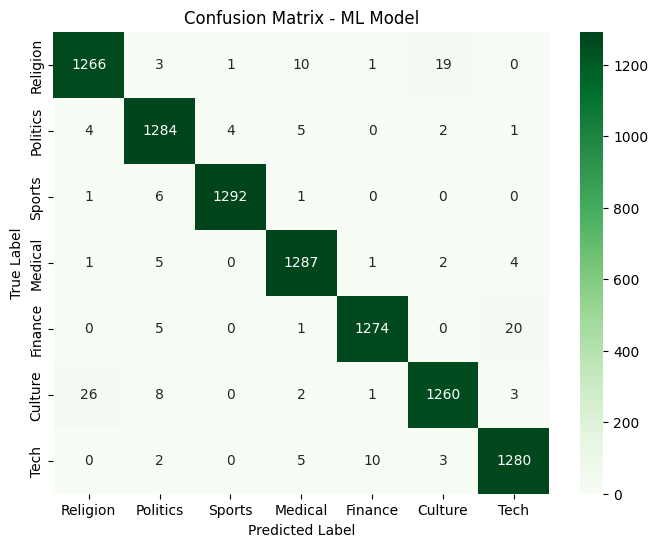

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_ml = confusion_matrix(y_test, y_pred_ml)

plt.figure(figsize=(8,6))
sns.heatmap(cm_ml, annot=True, fmt='d',
            xticklabels=class_names,
            yticklabels=class_names,
            cmap='Greens')

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - ML Model')
plt.show()

In [ ]:
def predict_category_ml(text):
    vec = vectorizer.transform([text])
    prediction = model_ml.predict(vec)

    predicted_class = prediction[0]

    return class_names[predicted_class]

text = "حقق المنتخب فوزا مهما في المباراة النهائية"

category_ml = predict_category_ml(text)

print("ML Predicted Category:", category_ml)

ML Predicted Category: Sports


In [ ]:
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(X_train_seq, maxlen=max_len, padding='post', truncating='post')
X_test_pad = pad_sequences(X_test_seq, maxlen=max_len, padding='post', truncating='post')

Build LSTM Model

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

model = Sequential([
    Embedding(input_dim=max_words, output_dim=128, input_length=max_len),
    LSTM(128),
    Dropout(0.5),
    Dense(64, activation='relu'),
    Dense(7, activation='softmax')
])

model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [ ]:
history = model.fit(
    X_train_pad, y_train,
    validation_split=0.1,
    epochs=20,
    batch_size=64
)

Epoch 1/20
512/512 ━━━━━━━━━━━━━━━━━━━━ 15s 14ms/step - accuracy: 0.6304 - loss: 0.9280 - val_accuracy: 0.7821 - val_loss: 0.7526
Epoch 2/20
512/512 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.7410 - loss: 0.6473 - val_accuracy: 0.8478 - val_loss: 0.4605
Epoch 3/20
512/512 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.8691 - loss: 0.4164 - val_accuracy: 0.9209 - val_loss: 0.2730
Epoch 4/20
512/512 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.8676 - loss: 0.4356 - val_accuracy: 0.8615 - val_loss: 0.4256
Epoch 5/20
512/512 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.9260 - loss: 0.2828 - val_accuracy: 0.8808 - val_loss: 0.4751
Epoch 6/20
512/512 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.9661 - loss: 0.1352 - val_accuracy: 0.9511 - val_loss: 0.2050
Epoch 7/20
512/512 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.9791 - loss: 0.0938 - val_accuracy: 0.9492 - val_loss: 0.2148
Epoch 8/20
512/512 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.9897 - loss: 0.0454 - val_acc

In [ ]:
loss, accuracy = model.evaluate(X_test_pad, y_test)
print("Test Accuracy:", accuracy)

285/285 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9534 - loss: 0.2792
Test Accuracy: 0.953406572341919


In [ ]:
import numpy as np
from sklearn.metrics import classification_report

y_pred_probs = model.predict(X_test_pad)
y_pred = np.argmax(y_pred_probs, axis=1)

class_names = ['Religion', 'Politics', 'Sports', 'Medical', 'Finance', 'Culture', 'Tech']

print(classification_report(y_test, y_pred, target_names=class_names))

285/285 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
              precision    recall  f1-score   support

    Religion       0.96      0.89      0.92      1300
    Politics       0.93      0.98      0.95      1300
      Sports       0.99      0.99      0.99      1300
     Medical       0.96      0.97      0.96      1300
     Finance       0.97      0.97      0.97      1300
     Culture       0.91      0.94      0.93      1300
        Tech       0.94      0.94      0.94      1300

    accuracy                           0.95      9100
   macro avg       0.95      0.95      0.95      9100
weighted avg       0.95      0.95      0.95      9100



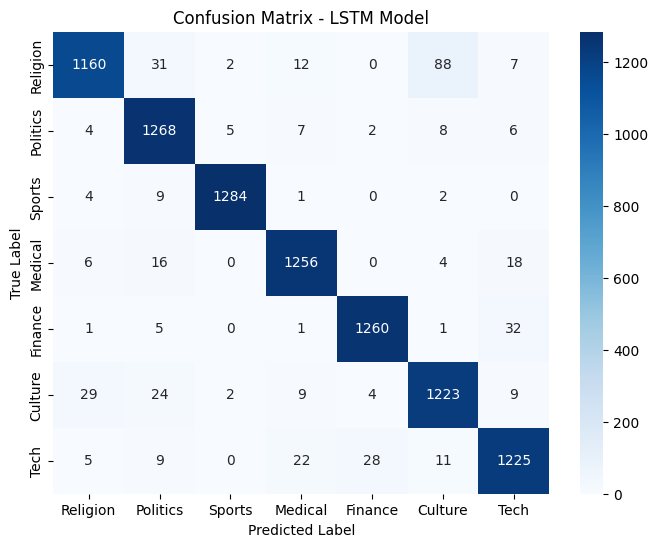

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=class_names,
            yticklabels=class_names,
            cmap='Blues')

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - LSTM Model')
plt.show()

In [ ]:
def predict_category(text):
    seq = tokenizer.texts_to_sequences([text])
    pad = pad_sequences(seq, maxlen=max_len, padding='post', truncating='post')

    prediction = model.predict(pad)
    predicted_class = np.argmax(prediction, axis=1)[0]
    confidence = np.max(prediction)

    return class_names[predicted_class], confidence

text = "حقق المنتخب فوزا مهما في المباراة النهائية"
category, confidence = predict_category(text)

print("Predicted Category:", category)
print("Confidence:", confidence)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
Predicted Category: Sports
Confidence: 0.99999547


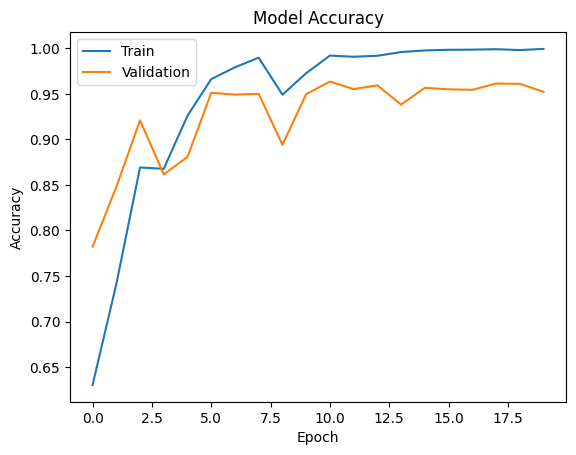

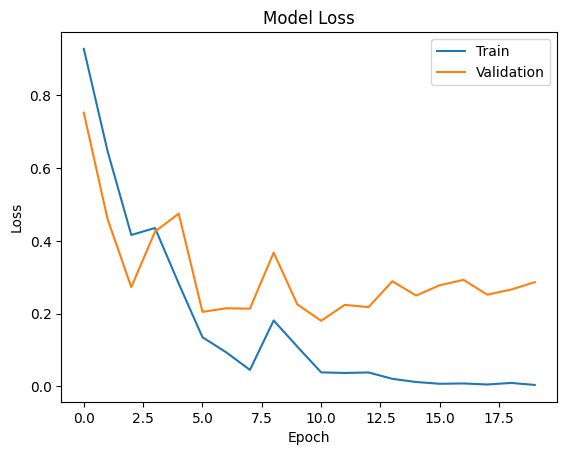

In [ ]:
# Accuracy
plt.figure()
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend(["Train", "Validation"])
plt.show()

# Loss
plt.figure()
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend(["Train", "Validation"])
plt.show()

LSTM vs SVM

In [ ]:
print(" FINAL COMPARISON ")
print("LSTM Accuracy:", accuracy)
print("SVM Accuracy:", accuracy_ml)

 FINAL COMPARISON 
LSTM Accuracy: 0.953406572341919
SVM Accuracy: 0.9827472527472527


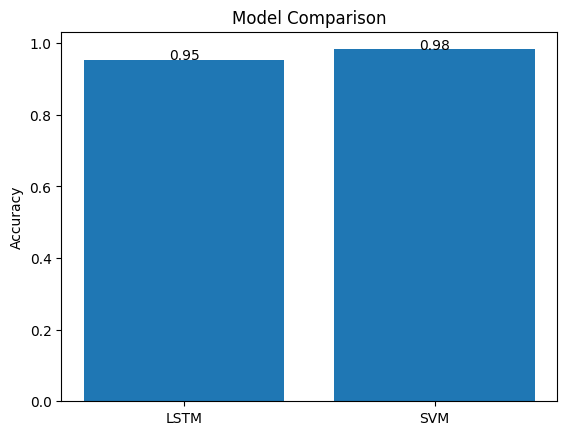

In [ ]:
models = ['LSTM', 'SVM']
accuracies = [accuracy, accuracy_ml]

plt.figure()
plt.bar(models, accuracies)
plt.ylabel("Accuracy")
plt.title("Model Comparison")

for i, v in enumerate(accuracies):
    plt.text(i, v, f"{v:.2f}", ha='center')

plt.show()

user input

In [ ]:
# Reverse mapping (number → label name)
reverse_mapping = {
    0: 'Religion',
    1: 'Politics',
    2: 'Sports',
    3: 'Medical',
    4: 'Finance',
    5: 'Culture',
    6: 'Tech'
}


# LSTM Prediction Function
def predict_lstm(text):
    seq = tokenizer.texts_to_sequences([text])
    pad = pad_sequences(seq, maxlen=max_len, padding='post', truncating='post')

    prediction = model.predict(pad)
    predicted_class = np.argmax(prediction, axis=1)[0]
    confidence = np.max(prediction)

    return reverse_mapping[predicted_class], confidence



# ML (SVM) Prediction Function
def predict_ml(text):
    vec = vectorizer.transform([text])
    prediction = model_ml.predict(vec)[0]

    return reverse_mapping[prediction]


# User Input

user_text = input("Enter your text: ")

# LSTM prediction
lstm_category, lstm_conf = predict_lstm(user_text)

# ML prediction
ml_category = predict_ml(user_text)


# Results

print("\n🔹 LSTM Result:")
print("Predicted Category:", lstm_category)
print("Confidence:", lstm_conf)

print("\n🔹 SVM (ML) Result:")
print("Predicted Category:", ml_category)



# Comparison
if lstm_category == ml_category:
    print("\n✅ Both models agree on the prediction")
else:
    print("\n⚠️ The models gave different predictions")